# Taller 2
## Aprendizaje de Máquina para el Análisis del Rendimiento de Ventas en Comercio Electrónico
### Parte 0: Preparación
#### 0.1. Adquisición y limpieza de datos

In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import sqlite3
# Scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.decomposition import PCA
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, roc_auc_score,
                             silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             mean_absolute_error, root_mean_squared_error, r2_score,
                             mean_absolute_percentage_error)

*Fuente de datos: Online Retail II del Repositorio de 
Aprendizaje Automático de UCI Irvine Machine Learning Repository 
(https://archive.ics.uci.edu/ml/datasets/Online+Retail+II)*

**Primer vistazo a la información**

El archivo `online_retail_II.xlsx` trae dos hojas ('Year 2009-2010' y 'Year 2010-2011'). Se cargan ambas con los tipos de dato declarados en la página fuente y se unen en una sola tabla. Para reutilizar el código del Taller 1, se homologan los nombres de columnas: `Invoice` → `InvoiceNo`, `Price` → `UnitPrice` y `Customer ID` → `CustomerID`.

In [2]:
# Carga de las dos hojas del archivo
hojas = pd.read_excel('online_retail_II.xlsx', sheet_name = None, engine = 'calamine', dtype = {
    'Invoice': str,
    'StockCode': str,
    'Description': str,
    'Quantity': 'int64',
    'InvoiceDate': 'datetime64[ns]',
    'Price': 'float64',
    'Customer ID': str,
    'Country': str})
for hoja, datos in hojas.items():
    print(hoja, datos.shape, "|", datos['InvoiceDate'].min(), "a", datos['InvoiceDate'].max())
#
df_or = pd.concat(hojas.values(), ignore_index = True)
# Homologación de nombres con el Taller 1
df_or = df_or.rename(columns = {'Invoice': 'InvoiceNo', 'Price': 'UnitPrice', 'Customer ID': 'CustomerID'})
df_or.head()

Year 2009-2010 (525461, 8) | 2009-12-01 07:45:00 a 2010-12-09 20:01:00
Year 2010-2011 (541910, 8) | 2010-12-01 08:26:00 a 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


In [3]:
df_or.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   InvoiceNo    1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   UnitPrice    1067371 non-null  float64       
 6   CustomerID   824364 non-null   str           
 7   Country      1067371 non-null  str           
dtypes: datetime64[ns](1), float64(1), int64(1), str(5)
memory usage: 121.4 MB


In [4]:
df_or.describe(include = 'all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,1067371,1067371,1062989,1.067371e+06,1067371,1.067371e+06,824364,1067371
unique,53628,5305,5698,NaN,NaN,NaN,5942,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,17841,United Kingdom
freq,1350,5829,5918,NaN,NaN,NaN,13097,981330
mean,NaN,NaN,NaN,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,NaN,NaN
min,NaN,NaN,NaN,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,NaN,NaN
25%,NaN,NaN,NaN,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,NaN,NaN
50%,NaN,NaN,NaN,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,NaN,NaN
75%,NaN,NaN,NaN,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,NaN,NaN
max,NaN,NaN,NaN,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,NaN,NaN


In [5]:
df_or.isna().sum()

InvoiceNo           0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     243007
Country             0
dtype: int64

**Limpieza:**
- Se consideró la información declarada en la página fuente del conjunto de datos. Por ello, se cargaron los tipos de dato declarados como primer paso;
- También se transformaron las variables tipo texto a mayúsculas y se quitaron los espacios antes y después del texto que pudieran existir;
- Se eliminaron los registros duplicados, entendidos como filas completamente iguales, conservando solo la primera ocurrencia;
- Se depuraron las cancelaciones (facturas con prefijo 'C') emparejándolas con su compra original y eliminando ambos registros; y
- Sobre los datos con NA, para el análisis exploratorio se los mantiene: para la descripción se asume que son ítems sin registro completo en el sistema, y para los identificadores de clientes, se consideró que fueron compras al consumidor final. Para los modelos que trabajan a nivel de cliente (Partes 1 y 2) sí se excluyen.

In [6]:
df_cl = df_or.copy()
# Tratando los campos tipo texto
cols_texto = df_cl.select_dtypes(include=['object', 'string']).columns
# Transformación a mayúsculas y quitando espacios
df_cl[cols_texto] = df_cl[cols_texto].apply(lambda col: col.str.strip().str.upper())

**Registros duplicados**

Se consideran duplicadas las filas completamente iguales (todas las columnas), y se conserva la primera. Se revisa además cuántos de ellos caen en el periodo que se repite entre las dos hojas del archivo (01/12/2010 al 09/12/2010).

In [7]:
# Registros duplicados (filas completamente iguales), se conserva la primera ocurrencia
esDup = df_cl.duplicated(keep = 'first')
nDup = esDup.sum()
# Periodo compartido entre las dos hojas
iniTraslape, finTraslape = hojas['Year 2010-2011']['InvoiceDate'].min(), hojas['Year 2009-2010']['InvoiceDate'].max()
dupTraslape = (esDup & df_cl['InvoiceDate'].between(iniTraslape, finTraslape)).sum()
#
print("Registros totales:", len(df_cl),
      "\nRegistros duplicados:", nDup, "(", round(nDup * 100 / len(df_cl), 2), "% )",
      "\nDuplicados dentro del traslape entre hojas:", dupTraslape,
      "\nDuplicados fuera del traslape:", nDup - dupTraslape)
#
df_cl = df_cl.loc[~esDup].reset_index(drop = True)
print("Registros después de quitar duplicados:", len(df_cl))

Registros totales: 1067371 
Registros duplicados: 34335 ( 3.22 % ) 
Duplicados dentro del traslape entre hojas: 22844 
Duplicados fuera del traslape: 11491
Registros después de quitar duplicados: 1033036


**Cancelaciones**

Las cancelaciones se identifican con una 'C' antes del código de la factura. Primero se verifica si existe la factura original con el mismo código sin la 'C'.

In [8]:
# Venta total por línea
df_cl['TotalSale'] = df_cl['Quantity'] * df_cl['UnitPrice']
# Identificación de cancelaciones
esCancel = df_cl['InvoiceNo'].str.startswith('C')
facturasC = df_cl.loc[esCancel, 'InvoiceNo'].drop_duplicates()
#
print("Líneas de cancelación:", esCancel.sum(),
      "\nFacturas de cancelación:", len(facturasC),
      "\nFacturas C cuyo código sin la 'C' existe como factura:", facturasC.str[1:].isin(df_cl['InvoiceNo']).sum(),
      "\nLíneas de cancelación sin cliente registrado:", (esCancel & df_cl['CustomerID'].isna()).sum())

Líneas de cancelación: 19104 
Facturas de cancelación: 8292 
Facturas C cuyo código sin la 'C' existe como factura: 0 
Líneas de cancelación sin cliente registrado: 714


Ninguna factura de cancelación comparte código con una factura de venta: en este conjunto de datos las facturas 'C' tienen numeración propia. Por esto, la regla de emparejamiento se aplica por **cliente, producto y monto absoluto igual**:

- Una línea de cancelación anula a una línea de compra del mismo `CustomerID`, del mismo `StockCode` y con el mismo monto en valor absoluto (`|Quantity × UnitPrice|`);
- Dentro de cada combinación, cancelaciones y compras se emparejan en orden cronológico (la primera cancelación con la primera compra, y así sucesivamente), de modo que cada compra se usa una sola vez;
- La compra debe ser anterior o simultánea a la cancelación; y
- Se eliminan ambos registros del par. Las cancelaciones parciales (montos distintos) o sin cliente no se emparejan y se mantienen en la base limpia como movimientos negativos.

In [9]:
# Emparejamiento de cancelaciones con su compra original
## Llave: mismo cliente, mismo producto y mismo monto absoluto
df_cl['Monto'] = df_cl['TotalSale'].abs().round(4)
llaves = ['CustomerID', 'StockCode', 'Monto']
## Cancelaciones y compras (con cliente) enumeradas en orden cronológico dentro de cada llave
canc = df_cl.loc[esCancel & df_cl['CustomerID'].notna()].sort_values('InvoiceDate').copy()
canc['nOrden'] = canc.groupby(llaves).cumcount()
vent = df_cl.loc[~esCancel & df_cl['CustomerID'].notna() & (df_cl['Quantity'] > 0)].sort_values('InvoiceDate').copy()
vent['nOrden'] = vent.groupby(llaves).cumcount()
## La n-ésima cancelación se empareja con la n-ésima compra de la misma llave
pares = canc.reset_index().merge(vent.reset_index(), on = llaves + ['nOrden'], suffixes = ('_c', '_v'))
## La compra debe ser anterior o simultánea a la cancelación
pares = pares.loc[pares['InvoiceDate_v'] <= pares['InvoiceDate_c']]
#
print("Cancelaciones con cliente:", len(canc),
      "\nCancelaciones emparejadas:", len(pares), "(", round(len(pares) * 100 / len(canc), 2), "% )",
      "\nMonto cancelado emparejado [£]:", round(pares['Monto'].sum(), 2),
      "\nMonto cancelado total [£]:", round(-df_cl.loc[esCancel, 'TotalSale'].sum(), 2))
#
# Eliminación de ambos registros de cada par
idxElim = pd.Index(pares['index_c']).union(pd.Index(pares['index_v']))
df_cl = df_cl.drop(index = idxElim).drop(columns = 'Monto').reset_index(drop = True)
print("Registros eliminados:", len(idxElim), "| Registros finales:", len(df_cl))

Cancelaciones con cliente: 18390 
Cancelaciones emparejadas: 6086 ( 33.09 % ) 
Monto cancelado emparejado [£]: 587579.88 
Monto cancelado total [£]: 1462050.61
Registros eliminados: 12172 | Registros finales: 1020864


In [10]:
df_cl.info()

<class 'pandas.DataFrame'>
RangeIndex: 1020864 entries, 0 to 1020863
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   InvoiceNo    1020864 non-null  str           
 1   StockCode    1020864 non-null  str           
 2   Description  1016589 non-null  str           
 3   Quantity     1020864 non-null  int64         
 4   InvoiceDate  1020864 non-null  datetime64[ns]
 5   UnitPrice    1020864 non-null  float64       
 6   CustomerID   785713 non-null   str           
 7   Country      1020864 non-null  str           
 8   TotalSale    1020864 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), str(5)
memory usage: 124.0 MB


In [11]:
df_cl.describe(include = 'all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSale
count,1020864,1020864,1016589,1.020864e+06,1020864,1.020864e+06,785713,1020864,1.020864e+06
unique,51657,5130,5621,NaN,NaN,NaN,5928,43,NaN
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,17841,UNITED KINGDOM,NaN
freq,1114,5684,5672,NaN,NaN,NaN,12332,938329,NaN
mean,NaN,NaN,NaN,1.019703e+01,2011-01-03 23:12:56.474927360,4.527967e+00,NaN,NaN,1.847017e+01
min,NaN,NaN,NaN,-9.600000e+03,2009-12-01 07:45:00,-5.359436e+04,NaN,NaN,-5.359436e+04
25%,NaN,NaN,NaN,1.000000e+00,2010-07-05 13:01:00,1.250000e+00,NaN,NaN,3.750000e+00
50%,NaN,NaN,NaN,3.000000e+00,2010-12-09 14:09:00,2.100000e+00,NaN,NaN,9.950000e+00
75%,NaN,NaN,NaN,1.000000e+01,2011-07-27 15:16:00,4.130000e+00,NaN,NaN,1.770000e+01
max,NaN,NaN,NaN,1.915200e+04,2011-12-09 12:50:00,3.897000e+04,NaN,NaN,3.897000e+04


In [12]:
# Guardado en una base SQLite
#with sqlite3.connect('taller2.sqlite') as conn:
#    df_cl.to_sql('df_limpio', conn, if_exists='replace', index=False)

#### 0.2. Análisis exploratorio de datos


**Sobre la limpieza**

- El archivo original tiene 1.067.371 registros. Se encontraron 34.335 duplicados (3,22 %): 22.844 corresponden al periodo del 01/12/2010 al 09/12/2010, que aparece en ambas hojas del archivo, y 11.491 son duplicados dentro de una misma hoja.

- Existen 19.104 líneas de cancelación en 8.292 facturas. Ninguna factura 'C' tiene una factura de venta con el mismo código, por lo que se emparejaron por cliente, producto y monto. Se emparejaron 6.086 de las 18.390 cancelaciones con cliente (33,09 %), equivalentes a £587.580 de los £1.462.051 cancelados. Las restantes son cancelaciones parciales, sin cliente o de compras anteriores al periodo, y se mantienen como movimientos negativos. La base limpia queda con 1.020.864 registros.

**Sobre los datos categóricos**

- Existen 5 campos con datos categóricos (forzados a tipo str durante la carga): número de factura, código de mercadería, descripción de mercadería, identificador de cliente y país de venta.

- Se observa la incongruencia entre códigos y descripciones: 5.130 códigos frente a 5.621 descripciones en la base limpia. Por esto, los análisis siguientes se hacen por código.

- Además de productos, la columna `StockCode` contiene códigos de servicio o ajuste ('DOT' y 'POST' para envío, 'M' para ajustes manuales, 'B' para deudas incobrables, 'BANK CHARGES', 'AMAZONFEE', 'TEST001', etc.). En la tabla de productos con mayor valor de venta aparecen 'DOT' y 'M' entre los tres primeros, por lo que para el modelado se filtran.

- Los valores NaN se presentan solo en 'Description' (4.382 en la base original) y 'CustomerID' (243.007). Las ventas sin cliente registrado representan el 15,6 % de las ventas efectivas.

- Hay 5.928 clientes y 43 países en la base limpia. El Reino Unido concentra la mayor parte de las ventas (£15,99 millones y 5.401 clientes), seguido de Irlanda (EIRE) y Países Bajos, ambos con muy pocos clientes de alto volumen.

**Sobre los datos numéricos**

- La cantidad y el precio unitario se concentran en valores pequeños (mediana de 3 unidades y £2,10). Los valores negativos en cantidad corresponden a las cancelaciones que no pudieron emparejarse.

- Los precios unitarios extremos negativos (£-53.594 y £-44.032) son ajustes de deuda incobrable ('ADJUST BAD DEBT', facturas con prefijo 'A'), y los extremos positivos (£38.970 y £25.111) son cancelaciones de ajustes manuales sin compra equivalente en la base.

- El conjunto de datos cubre dos años: del 01/12/2009 al 09/12/2011. Diciembre de 2011 está incompleto.

In [13]:
# Base del análisis exploratorio
df = df_cl

In [14]:
# Confirmación de datos extremos para precios unitarios
print(df.loc[df['UnitPrice'].nsmallest(2).index])
print(df.loc[df['UnitPrice'].nlargest(2).index])

       InvoiceNo StockCode      Description  Quantity         InvoiceDate  \
175072   A506401         B  ADJUST BAD DEBT         1 2010-04-29 13:36:00   
269348   A516228         B  ADJUST BAD DEBT         1 2010-07-19 11:24:00   

        UnitPrice CustomerID         Country  TotalSale  
175072  -53594.36        NaN  UNITED KINGDOM  -53594.36  
269348  -44031.79        NaN  UNITED KINGDOM  -44031.79  
       InvoiceNo StockCode Description  Quantity         InvoiceDate  \
708075   C556445         M      MANUAL        -1 2011-06-10 15:31:00   
235708   C512770         M      MANUAL        -1 2010-06-17 16:52:00   

        UnitPrice CustomerID         Country  TotalSale  
708075   38970.00      15098  UNITED KINGDOM  -38970.00  
235708   25111.09      17399  UNITED KINGDOM  -25111.09  


In [15]:
# Rango temporal del conjunto de datos
print("Rango temporal:", df['InvoiceDate'].min(),
      " a ", df['InvoiceDate'].max())

Rango temporal: 2009-12-01 07:45:00  a  2011-12-09 12:50:00


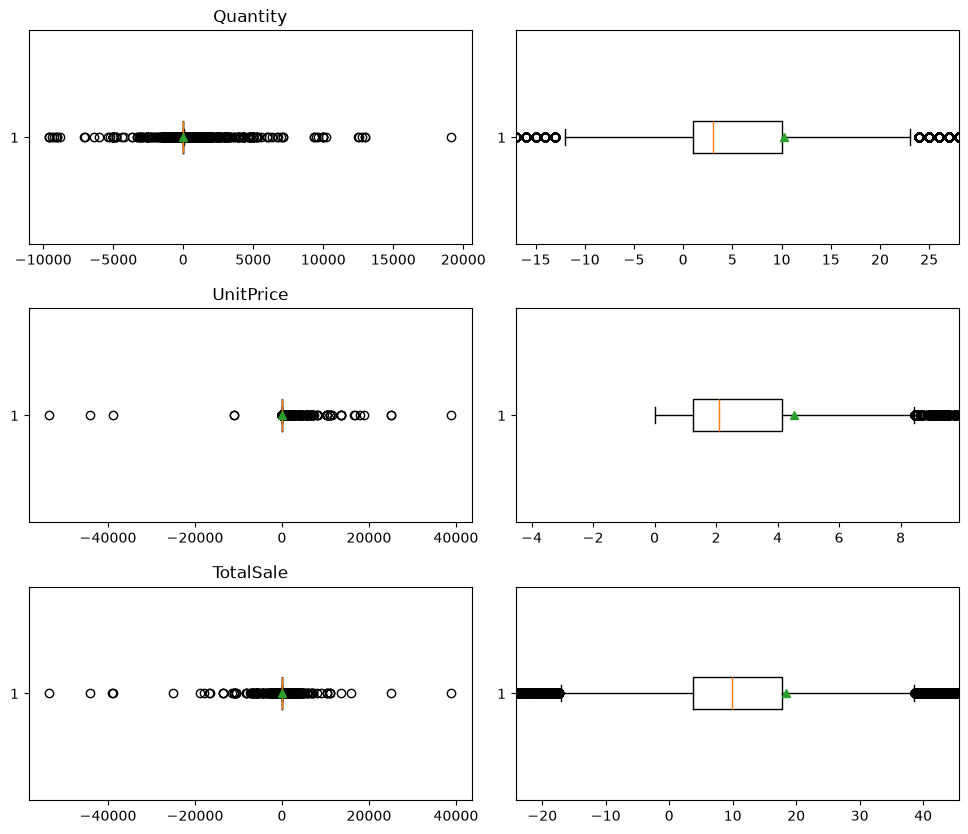

In [16]:
# Boxplots
fig, axs = plt.subplots(3, 2, figsize = (12, 10))
# 1. Quantity
axs[0, 0].boxplot(df['Quantity'], orientation = 'horizontal', showmeans = True)
axs[0, 0].set_title('Quantity')
# 2. UnitPrice
axs[1, 0].boxplot(df['UnitPrice'], orientation = 'horizontal', showmeans = True)
axs[1, 0].set_title('UnitPrice')
# 3. TotalSale
axs[2, 0].boxplot(df['TotalSale'], orientation = 'horizontal', showmeans = True)
axs[2, 0].set_title('TotalSale')
# 1.1. Ampliación Quantity
#
def iqr_lim(dataFrame):
    q1, q3 = dataFrame.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    return (iqr, lim_inf, lim_sup)
iqr1, lim_inf1, lim_sup1 = iqr_lim(df['Quantity'])
#
axs[0, 1].boxplot(df['Quantity'], orientation = 'horizontal', showmeans = True)
axs[0, 1].set_xlim(lim_inf1 - 0.5 * iqr1, lim_sup1 + 0.5 * iqr1)
# 2.1. Ampliación UnitPrice
iqr2, lim_inf2, lim_sup2 = iqr_lim(df['UnitPrice'])
#
axs[1, 1].boxplot(df['UnitPrice'], orientation = 'horizontal', showmeans = True)
axs[1, 1].set_xlim(lim_inf2 - 0.5 * iqr2, lim_sup2 + 0.5 * iqr2)
# 3.1. Ampliación TotalSale
iqr3, lim_inf3, lim_sup3 = iqr_lim(df['TotalSale'])
#
axs[2, 1].boxplot(df['TotalSale'], orientation = 'horizontal', showmeans = True)
axs[2, 1].set_xlim(lim_inf3 - 0.5 * iqr3, lim_sup3 + 0.5 * iqr3)
plt.subplots_adjust(hspace = 0.3, wspace = 0.1)
plt.show()

In [17]:
# Suma total por países
countryTot = df.groupby('Country').agg(
    totSaleCountry = ('TotalSale', 'sum'),
    nCustomers = ('CustomerID', 'nunique')
).sort_values('totSaleCountry', ascending = False).reset_index()
#
print("Top países con mejor cartera:\n", countryTot.head(3),
      "\n\nPaíses con cartera a revisar:\n", countryTot.tail(3),
     "\n________________________________________________\n")
#
# Suma total por consumidor registrado
customerTot = df.groupby(['CustomerID'])['TotalSale'].sum().sort_values(ascending = False).reset_index()
customerTot = customerTot.merge(df[['CustomerID','Country']].drop_duplicates('CustomerID'),
                                on = 'CustomerID', how = 'left')
#
print("Mejores clientes:\n", customerTot.head(5),
     "\n________________________________________________\n\n",
     "Clientes con cartera a revisar:\n", customerTot.tail(10),
     "\n________________________________________________\n")
#
# Ventas efectivas
df_ef = df.loc[df['TotalSale'] > 0]
# Cuánto representa la venta efectiva con clientes no registrados
customerNan = (
    df_ef.groupby(df_ef['CustomerID'].isna())['TotalSale'].sum().rename(index = {True: 'ND', False: 'D'}).to_frame('sumTotSale')
)
#
percCustomerNan = round(customerNan.at['ND', 'sumTotSale'] * 100 / customerNan['sumTotSale'].sum(), 2)
print("Clientes no registrados con ventas efectivas:\n", percCustomerNan, "%",
     "\n________________________________________________\n")
# Producto más vendido
codeTot = df_ef.groupby(['StockCode'])['TotalSale'].sum().sort_values(ascending = False).reset_index()
#
print("Productos con mayor valor en ventas:\n", codeTot.head(5),
     "\n________________________________________________\n\n",
     "Productos con menor valor en ventas:\n", codeTot.tail(5),
     "\n________________________________________________\n")

Top países con mejor cartera:
           Country  totSaleCountry  nCustomers
0  UNITED KINGDOM    1.598606e+07        5401
1            EIRE    6.099538e+05           5
2     NETHERLANDS    5.483307e+05          23 

Países con cartera a revisar:
          Country  totSaleCountry  nCustomers
40   WEST INDIES          536.41           1
41  SAUDI ARABIA          131.17           1
42       NIGERIA           -6.66           1 
________________________________________________

Mejores clientes:
   CustomerID  TotalSale         Country
0      18102  570380.61  UNITED KINGDOM
1      14646  523342.07     NETHERLANDS
2      14156  296063.44            EIRE
3      14911  265757.91            EIRE
4      17450  231390.55  UNITED KINGDOM 
________________________________________________

 Clientes con cartera a revisar:
      CustomerID  TotalSale         Country
5918      15202   -2570.18  UNITED KINGDOM
5919      17013   -3224.76  UNITED KINGDOM
5920      18023   -3248.86  UNITED KINGDOM
5921 

**Productos más vendidos y su tendencia en el tiempo**

Se toman los 5 productos con mayor cantidad vendida, considerando solo ventas efectivas y códigos de producto (5 dígitos iniciales; se excluyen códigos de servicio como 'POST', 'DOT' o 'M').

In [18]:
# Productos más vendidos (por cantidad), solo códigos de producto
nTop = 5
df_prod = df_ef.loc[df_ef['StockCode'].str.match(r'^\d{5}')]
topProd = df_prod.groupby('StockCode').agg(
    Quantity = ('Quantity', 'sum'),
    TotalSale = ('TotalSale', 'sum')
).sort_values('Quantity', ascending = False).head(nTop).reset_index()
## Descripción más frecuente de cada código
descTop = (df_prod.loc[df_prod['StockCode'].isin(topProd['StockCode'])]
           .groupby('StockCode')['Description'].agg(lambda x: x.mode().iat[0]))
topProd['Description'] = topProd['StockCode'].map(descTop)
topProd

,StockCode,Quantity,TotalSale,Description
0,84077,105755,24353.45,WORLD WAR 2 GLIDERS ASSTD DESIGNS
1,85099B,96268,181069.75,JUMBO BAG RED RETROSPOT
2,21212,94420,51585.55,PACK OF 72 RETROSPOT CAKE CASES
3,85123A,91355,252524.13,WHITE HANGING HEART T-LIGHT HOLDER
4,22197,88265,79347.30,SMALL POPCORN HOLDER


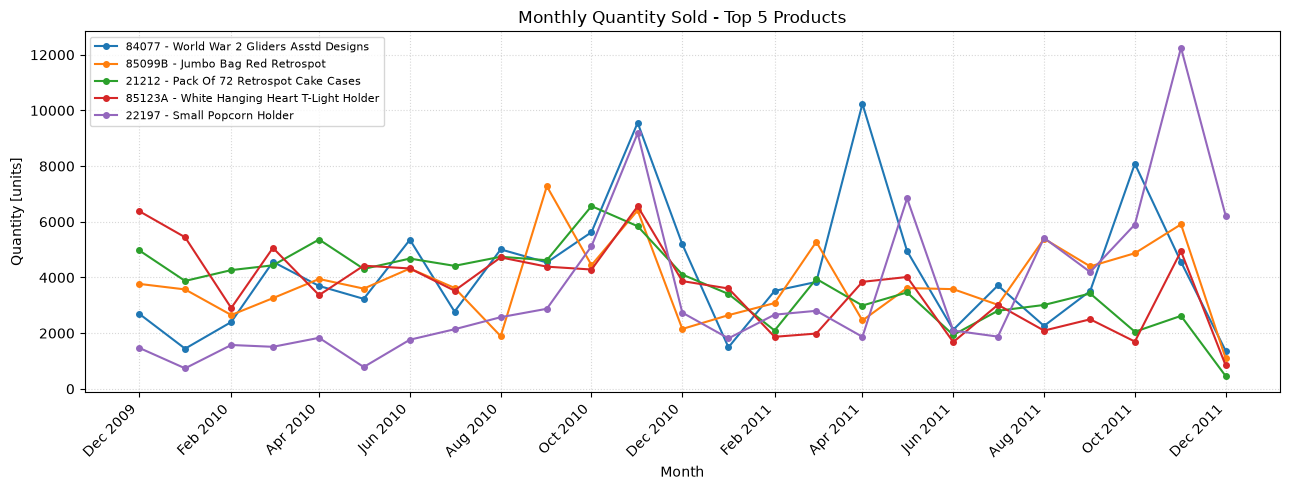

In [19]:
# Tendencia mensual de los productos más vendidos
prodMes = (df_prod.loc[df_prod['StockCode'].isin(topProd['StockCode'])]
           .groupby([df_prod['InvoiceDate'].dt.to_period('M'), 'StockCode'])['Quantity'].sum()
           .unstack('StockCode').fillna(0)[topProd['StockCode']])
#
fig, ax = plt.subplots(figsize = (13, 5))
for code in prodMes.columns:
    ax.plot(prodMes.index.to_timestamp(), prodMes[code], marker = 'o', markersize = 4,
            label = f"{code} - {descTop[code].title()}")
ax.set(xlabel = 'Month', ylabel = 'Quantity [units]',
       title = f'Monthly Quantity Sold - Top {nTop} Products')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval = 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.grid(linestyle = ':', alpha = 0.5)
ax.legend(fontsize = 8)
plt.xticks(rotation = 45, ha = 'right')
plt.tight_layout()
fig.savefig("top_products_trend.png")
plt.show()

- Los cinco productos con mayor cantidad vendida son de bajo precio unitario. Por valor de venta, en cambio, destaca 85123A.

- La mayoría presenta un pico en noviembre de 2010, en línea con la temporada navideña. El 84077 tiene picos aislados (abril y octubre de 2011) que sugieren compras mayoristas puntuales, y el 22197 gana participación durante 2011, con su máximo en noviembre de 2011.

#### 0.3. Visualización y estacionalidad

In [20]:
# Venta neta
periodTotSale = df['TotalSale'].sum()
#
print("Venta neta del periodo:", round(periodTotSale, 2))

Venta neta del periodo: 18855533.7


Las gráficas a continuación describen el movimiento de ventas para el periodo de referencia, por día y por mes. Permiten observar picos en ventas y momentos de desembolsos por cancelaciones de pedidos o ajustes de caja. Luego, se compara la venta del producto con mayor cantidad vendida en cada mes con respecto al total del mes, considerando solo ventas efectivas. Finalmente, se revisan los patrones estacionales por mes del año, día de la semana y hora.

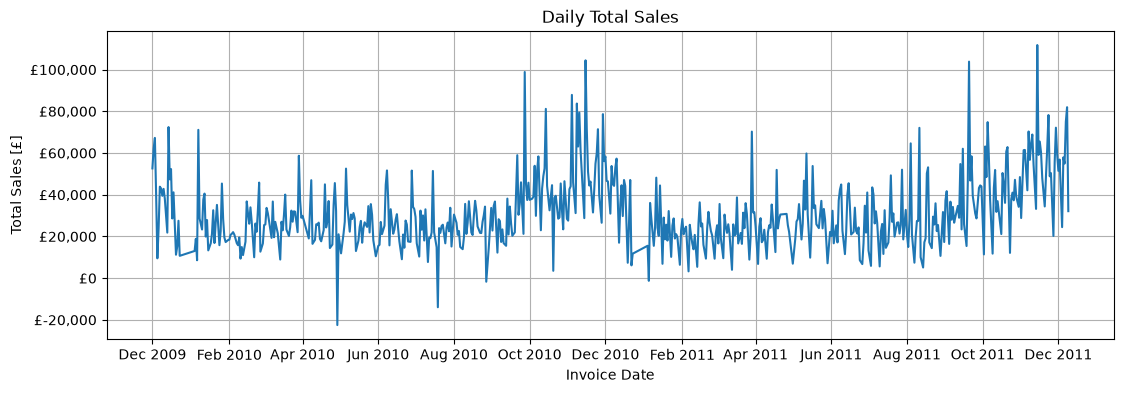

In [21]:
# Serie de tiempo ventas (suma diaria)
dailySales = df.groupby(df['InvoiceDate'].dt.normalize())['TotalSale'].sum()
t = dailySales.index
s = dailySales.values
#
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t, s)
ax.set(xlabel='Invoice Date', ylabel='Total Sales [£]',
       title='Daily Total Sales')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval = 2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'£{x:,.0f}'))
ax.grid()
fig.savefig("daily_total_sale.png")
plt.show()

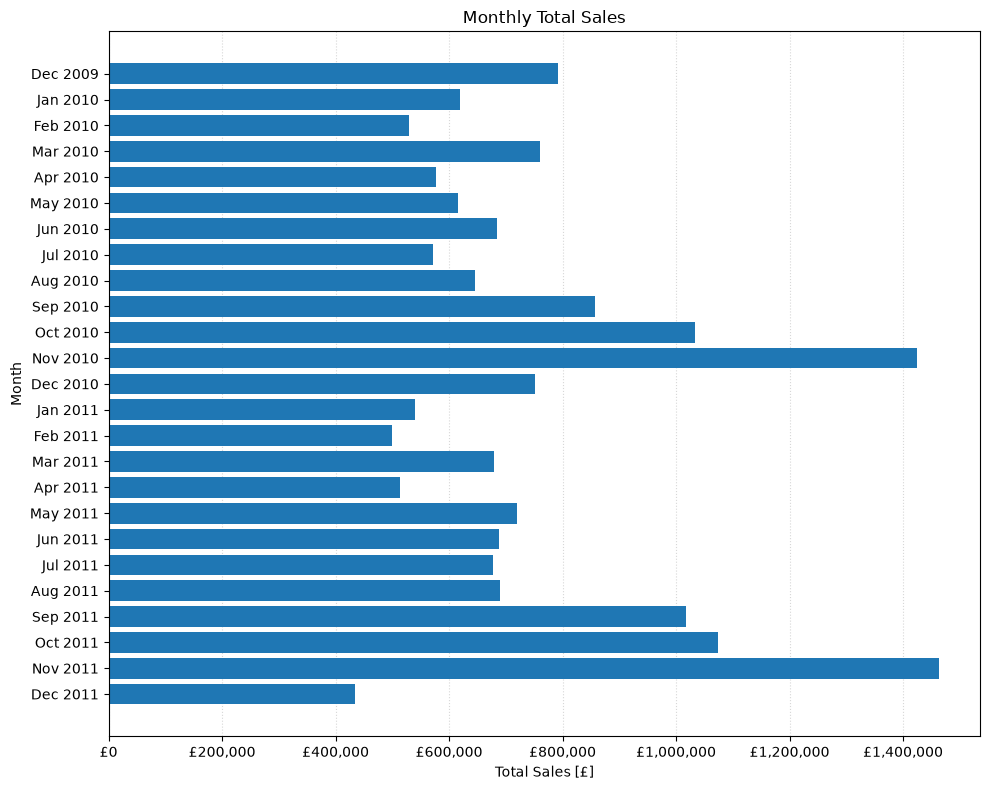

In [22]:
monthTotSales = df.groupby(df['InvoiceDate'].dt.to_period('M'))['TotalSale'].sum()
#
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(monthTotSales.index.strftime('%b %Y'), monthTotSales.values)
ax.invert_yaxis()
ax.set(xlabel='Total Sales [£]', ylabel='Month',
       title='Monthly Total Sales')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'£{x:,.0f}'))
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig("monthly_total_sales.png")
plt.show()

In [23]:
# Ventas por mes, con articulo más vendido
## Totales por mes
df_mes = df_ef.copy()
df_mes['Month'] = df_mes['InvoiceDate'].dt.to_period('M')
monthProduct = df_mes.groupby('Month').agg(
    TotalItems = ('Quantity', 'sum'),
    TotalSales = ('TotalSale', 'sum')
).reset_index()
## Producto más vendido por mes
ventas_prod = df_mes.groupby(['Month', 'StockCode'], as_index = False).agg(
    Quantity = ('Quantity', 'sum'),
    TotalSale = ('TotalSale', 'sum')
)
top = (ventas_prod
       .sort_values('Quantity', ascending = False)
       .drop_duplicates('Month')
       .rename(columns = {'StockCode': 'TopStockCode', 'Quantity': 'TopQuantity', 'TotalSale': 'TopTotalSale'}))
## Descripciones (la más frecuente de cada código, igual que en la tabla de productos más vendidos)
desc = (df_mes.loc[df_mes['StockCode'].isin(top['TopStockCode'])]
          .groupby('StockCode')['Description'].agg(lambda x: x.mode().iat[0])
          .rename_axis('TopStockCode').reset_index())
## Tabla de resumen por mes
monthProduct = (monthProduct
           .merge(top, on = 'Month', how = 'left')
           .merge(desc, on = 'TopStockCode', how = 'left'))
monthProduct

,Month,TotalItems,TotalSales,TopStockCode,TopQuantity,TopTotalSale,Description
0,2009-12,420900,811797.940,85123A,6388,17202.25,WHITE HANGING HEART T-LIGHT HOLDER
1,2010-01,387631,633126.702,20993,9500,996.77,JAZZ HEARTS MEMO PAD
2,2010-02,375832,540789.256,37410,19249,2022.53,BLACK AND WHITE PAISLEY FLOWER MUG
3,2010-03,522106,815947.511,21091,13119,1425.57,SET/6 WOODLAND PAPER PLATES
4,2010-04,355811,661642.942,21212,5364,2598.47,PACK OF 72 RETROSPOT CAKE CASES
5,2010-05,382743,638130.510,21982,5624,2684.60,PACK OF 12 SUKI TISSUES
6,2010-06,400325,737182.380,84077,5356,1048.32,WORLD WAR 2 GLIDERS ASSTD DESIGNS
7,2010-07,331822,634138.440,21212,4418,2262.41,PACK OF 72 RETROSPOT CAKE CASES
8,2010-08,382707,674509.560,84077,5009,960.37,WORLD WAR 2 GLIDERS ASSTD DESIGNS
9,2010-09,575081,905218.511,17003,13895,2632.55,BROCADE RING PURSE


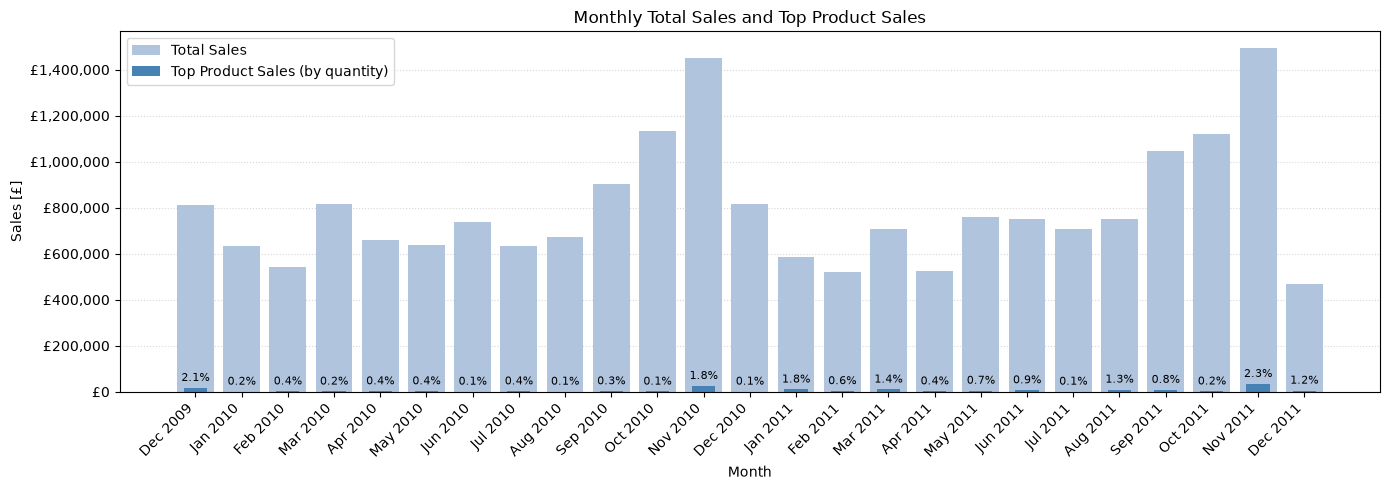

In [24]:
meses = monthProduct['Month'].dt.strftime('%b %Y')

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(meses, monthProduct['TotalSales'], label='Total Sales', color='lightsteelblue')
barras_top = ax.bar(meses, monthProduct['TopTotalSale'], label='Top Product Sales (by quantity)',
                    color='steelblue', width=0.5)

# Porcentaje que representa el producto top sobre el total del mes
prop = monthProduct['TopTotalSale'] / monthProduct['TotalSales']
ax.bar_label(barras_top, labels=[f'{p:.1%}' for p in prop], padding=3, fontsize=8)

ax.set(xlabel='Month', ylabel='Sales [£]',
       title='Monthly Total Sales and Top Product Sales')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'£{x:,.0f}'))
ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.set_axisbelow(True)
ax.legend()

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
fig.savefig("monthly_total_sales_product.png")
plt.show()

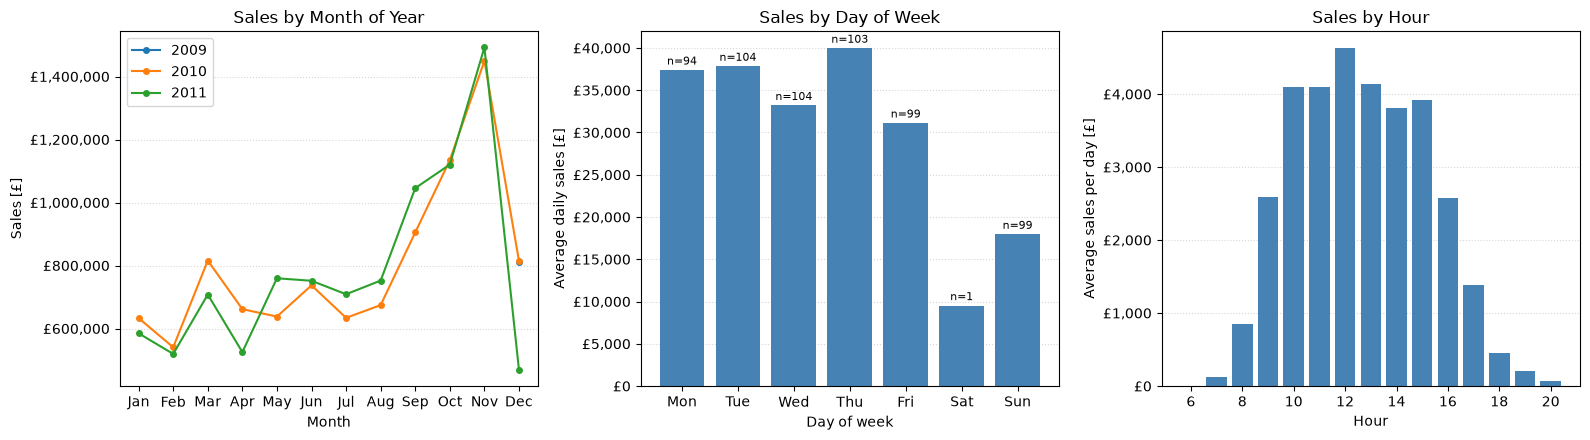

Meses con mayores ventas efectivas:
 InvoiceDate  InvoiceDate
11           2011           1492230.520
             2010           1449535.422
10           2010           1134422.800
             2011           1120517.130
9            2011           1045752.582
dtype: float64


In [25]:
# Patrones estacionales (ventas efectivas)
nombresMes = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
nombresDia = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
## Por mes del año, comparando años (diciembre 2011 está incompleto: hasta el día 9)
mesAnio = df_ef.groupby([df_ef['InvoiceDate'].dt.year, df_ef['InvoiceDate'].dt.month])['TotalSale'].sum().unstack(0)
## Promedio diario por día de la semana y por hora
ventaDia = df_ef.groupby(df_ef['InvoiceDate'].dt.normalize())['TotalSale'].sum()
diaSemana = ventaDia.groupby(ventaDia.index.dayofweek).mean().reindex(range(7), fill_value = 0)
horaDia = df_ef.groupby(df_ef['InvoiceDate'].dt.hour)['TotalSale'].sum() / ventaDia.size
#
fig, axs = plt.subplots(1, 3, figsize = (16, 4.5))
for anio in mesAnio.columns:
    axs[0].plot(mesAnio.index, mesAnio[anio], marker = 'o', markersize = 4, label = str(anio))
axs[0].set(xlabel = 'Month', ylabel = 'Sales [£]', title = 'Sales by Month of Year')
axs[0].set_xticks(range(1, 13), nombresMes)
axs[0].legend()
barrasDia = axs[1].bar(nombresDia, diaSemana.values, color = 'steelblue')
## Número de días con operación detrás de cada promedio
nDias = ventaDia.groupby(ventaDia.index.dayofweek).size().reindex(range(7), fill_value = 0)
axs[1].bar_label(barrasDia, labels = [f'n={n}' for n in nDias], padding = 2, fontsize = 8)
axs[1].set(xlabel = 'Day of week', ylabel = 'Average daily sales [£]', title = 'Sales by Day of Week')
axs[2].bar(horaDia.index, horaDia.values, color = 'steelblue')
axs[2].set(xlabel = 'Hour', ylabel = 'Average sales per day [£]', title = 'Sales by Hour')
for ax in axs:
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'£{x:,.0f}'))
    ax.grid(axis = 'y', linestyle = ':', alpha = 0.5)
    ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig("seasonality.png")
plt.show()
#
print("Meses con mayores ventas efectivas:\n", mesAnio.stack().sort_values(ascending = False).head(5))

- Las ventas tienen una estacionalidad marcada y muy similar entre 2010 y 2011: crecen desde septiembre y alcanzan su máximo en noviembre (ventas efectivas de £1,49 millones en noviembre de 2011 y £1,45 millones en noviembre de 2010). Los meses más bajos están en el primer semestre, especialmente febrero. La caída de diciembre de 2011 se debe a que solo hay datos hasta el día 9. La serie de 2009 tiene un solo punto (diciembre, £812 mil), que queda casi superpuesto al de diciembre de 2010 (£815 mil).

- Por día de la semana, de lunes a jueves se registran los promedios diarios más altos (jueves es el mayor). El domingo vende cerca de la mitad, y el sábado prácticamente no hay operación (un solo sábado con ventas en todo el periodo, por lo que esa barra no es representativa).

- Por hora, la actividad se concentra entre las 10:00 y las 15:00, con el máximo al mediodía, coherente con un comercio que vende principalmente a mayoristas en horario laboral.

#### 0.4. Base para modelado

Para los modelos se filtran las entradas irrelevantes sobre la base limpia:
- Se descartan las cancelaciones que no pudieron emparejarse (líneas con 'C'), pues no hay una compra en la base de la cual descontarlas;
- Se mantienen solo líneas con cantidad y precio unitario positivos;
- Se mantienen solo códigos de producto (5 dígitos iniciales), excluyendo cargos como envío ('POST', 'DOT'), ajustes manuales ('M', 'ADJUST'), comisiones ('BANK CHARGES', 'AMAZONFEE'), deudas incobrables ('B') o pruebas ('TEST'); y
- Para las Partes 1 y 2 se usan solo los registros con `CustomerID`. Para la Parte 3 se mantienen también las ventas al consumidor final, ya que también son ventas.

In [26]:
# Base de ventas válidas para modelado
esProducto = df['StockCode'].str.match(r'^\d{5}')
df_mod = df.loc[~df['InvoiceNo'].str.startswith('C') & (df['Quantity'] > 0) & (df['UnitPrice'] > 0) & esProducto].copy()
df_cli = df_mod.dropna(subset = ['CustomerID'])
#
print("Registros base limpia:", len(df),
      "\nRegistros para modelado (Parte 3):", len(df_mod),
      "\nRegistros con cliente (Partes 1 y 2):", len(df_cli),
      "\nClientes:", df_cli['CustomerID'].nunique())

Registros base limpia: 1020864 
Registros para modelado (Parte 3): 997224 
Registros con cliente (Partes 1 y 2): 770587 
Clientes: 5839


### Parte 1: Clasificación de clientes

**Definición de las categorías**

Se definen dos clasificaciones binarias independientes:
- **Premium por consumo:** clientes en el 20 % superior según el monto gastado; y
- **Premium por frecuencia:** clientes en el 20 % superior según el número de facturas.

Si la categoría se define con el gasto total y luego se entrena el modelo con ese mismo gasto (o con sus componentes, como frecuencia × ticket promedio), el clasificador solo reconstruiría la regla y no aprendería nada útil. Para evitarlo, se usa una división temporal:
- **Ventana de observación** (01/12/2009 al 31/05/2011): con ella se calculan las características de cada cliente (recencia, antigüedad, frecuencia, gasto, unidades, variedad de productos, ticket promedio, precio unitario promedio, cancelaciones y si es del Reino Unido); y
- **Ventana de etiqueta** (01/06/2011 al 09/12/2011): con ella se define si el cliente fue Premium. Un cliente que no volvió a comprar tiene consumo y frecuencia de cero.

Así, el modelo responde a una pregunta de negocio: con el historial de un cliente, ¿será Premium en los próximos meses? El umbral del 20 % (criterio de Pareto) queda como parámetro.

In [27]:
# Parámetros
fechaCorte = pd.Timestamp('2011-06-01')    # inicio de la ventana de etiqueta
pPremium = 0.80                            # percentil para definir Premium (top 20 %)
#
obs = df_cli.loc[df_cli['InvoiceDate'] < fechaCorte]
fut = df_cli.loc[df_cli['InvoiceDate'] >= fechaCorte]
print("Ventana de observación:", obs['InvoiceDate'].min().date(), "a", obs['InvoiceDate'].max().date(),
      "\nVentana de etiqueta:", fut['InvoiceDate'].min().date(), "a", fut['InvoiceDate'].max().date())
#
# Características por cliente (ventana de observación)
clientes = obs.groupby('CustomerID').agg(
    FirstDate = ('InvoiceDate', 'min'),
    LastDate = ('InvoiceDate', 'max'),
    Frequency = ('InvoiceNo', 'nunique'),
    Monetary = ('TotalSale', 'sum'),
    TotalItems = ('Quantity', 'sum'),
    nProducts = ('StockCode', 'nunique'),
    Country = ('Country', 'first')
)
clientes['Recency'] = (fechaCorte - clientes['LastDate']).dt.days
clientes['Tenure'] = (fechaCorte - clientes['FirstDate']).dt.days
clientes['AvgTicket'] = clientes['Monetary'] / clientes['Frequency']
clientes['AvgUnitPrice'] = clientes['Monetary'] / clientes['TotalItems']
clientes['IsUK'] = (clientes['Country'] == 'UNITED KINGDOM').astype(int)
## Cancelaciones no emparejadas del cliente en la ventana (posibles devoluciones)
cancObs = df.loc[df['InvoiceNo'].str.startswith('C') & (df['InvoiceDate'] < fechaCorte)]
clientes['nCancel'] = cancObs.groupby('CustomerID')['InvoiceNo'].nunique().reindex(clientes.index, fill_value = 0)
#
# Etiquetas (ventana de etiqueta): consumo y frecuencia futuros, 0 si el cliente no volvió a comprar
clientes['FutMonetary'] = fut.groupby('CustomerID')['TotalSale'].sum().reindex(clientes.index, fill_value = 0)
clientes['FutFrequency'] = fut.groupby('CustomerID')['InvoiceNo'].nunique().reindex(clientes.index, fill_value = 0)
limConsumo = clientes['FutMonetary'].quantile(pPremium)
limFrecuencia = clientes['FutFrequency'].quantile(pPremium)
clientes['PremiumConsumo'] = (clientes['FutMonetary'] > limConsumo).astype(int)
clientes['PremiumFrecuencia'] = (clientes['FutFrequency'] > limFrecuencia).astype(int)
#
print("\nClientes en la ventana de observación:", len(clientes),
      "\nUmbral Premium por consumo [£]:", round(limConsumo, 2),
      "| Proporción Premium:", round(clientes['PremiumConsumo'].mean() * 100, 2), "%",
      "\nUmbral Premium por frecuencia [facturas]:", limFrecuencia,
      "| Proporción Premium:", round(clientes['PremiumFrecuencia'].mean() * 100, 2), "%",
      "\nClientes Premium en ambas categorías:", (clientes['PremiumConsumo'] & clientes['PremiumFrecuencia']).sum())

Ventana de observación: 2009-12-01 a 2011-05-31 
Ventana de etiqueta: 2011-06-01 a 2011-12-09

Clientes en la ventana de observación: 4898 
Umbral Premium por consumo [£]: 948.02 | Proporción Premium: 20.01 % 
Umbral Premium por frecuencia [facturas]: 3.0 | Proporción Premium: 15.09 % 
Clientes Premium en ambas categorías: 627


In [28]:
# Perfil de cada categoría (promedios de la ventana de observación)
varsCli = ['Recency', 'Tenure', 'Frequency', 'Monetary', 'TotalItems', 'nProducts', 'AvgTicket', 'AvgUnitPrice', 'nCancel', 'IsUK']
pd.concat({
    'PremiumConsumo': clientes.groupby('PremiumConsumo')[varsCli].mean(),
    'PremiumFrecuencia': clientes.groupby('PremiumFrecuencia')[varsCli].mean()
}).round(2)

Recency  Tenure  Frequency  Monetary  \
                  PremiumConsumo                                         
PremiumConsumo    0                193.91  344.20       3.27   1027.95   
                  1                 63.79  405.97      12.86   7415.69   
PremiumFrecuencia 0                188.62  347.81       3.41   1236.21   
                  1                 51.13  405.81      15.20   8326.80   

                                  TotalItems  nProducts  AvgTicket  \
                  PremiumConsumo                                     
PremiumConsumo    0                   692.07      50.34     317.81   
                  1                  4398.80     148.68     548.15   
PremiumFrecuencia 0                   809.43      55.03     348.05   
                  1                  4947.13     154.37     453.11   

                                  AvgUnitPrice  nCancel  IsUK  
                  PremiumConsumo                               
PremiumConsumo    0                       2.32     0.49  0.93  
                  1                       1.90     2.56  0.88  
PremiumFrecuencia 0                       2.28     0.55  0.92  
                  1                       1.94     2.89  0.92

**Modelos de clasificación**

Para cada etiqueta se entrenan dos modelos con el 70 % de los clientes y se evalúan con el 30 % restante (división estratificada):
- **Regresión logística**, con transformación logarítmica y estandarización de las variables (están muy sesgadas); y
- **Bosque aleatorio**, que no requiere escalamiento y captura relaciones no lineales.

Ambos usan `class_weight = 'balanced'`, porque la clase Premium es minoritaria. Al estar desbalanceadas las clases, además de la exactitud se revisan la precisión, la sensibilidad (recall) y el F1 de la clase Premium, y el área bajo la curva ROC.

In [29]:
# Entrenamiento y evaluación de clasificadores para ambas etiquetas
X = clientes[varsCli]
modelos = {
    'Logistic Regression': Pipeline([('log', FunctionTransformer(np.log1p)),
                                     ('esc', StandardScaler()),
                                     ('modelo', LogisticRegression(max_iter = 1000, class_weight = 'balanced'))]),
    'Random Forest': RandomForestClassifier(n_estimators = 300, min_samples_leaf = 5, class_weight = 'balanced',
                                            random_state = 42, n_jobs = -1)
}
resultadosClf = []
predClf = {}
for etiqueta in ['PremiumConsumo', 'PremiumFrecuencia']:
    y = clientes[etiqueta]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, stratify = y, random_state = 42)
    for nombre, modelo in modelos.items():
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
        y_prob = modelo.predict_proba(X_test)[:, 1]
        predClf[(etiqueta, nombre)] = (y_test, y_pred)
        rep = classification_report(y_test, y_pred, output_dict = True)
        resultadosClf.append({'Etiqueta': etiqueta, 'Modelo': nombre,
                              'Accuracy': rep['accuracy'],
                              'Precision Premium': rep['1']['precision'],
                              'Recall Premium': rep['1']['recall'],
                              'F1 Premium': rep['1']['f1-score'],
                              'ROC AUC': roc_auc_score(y_test, y_prob)})
        print(etiqueta, "-", nombre, "\n", classification_report(y_test, y_pred, target_names = ['Normal', 'Premium']))
#
resultadosClf = pd.DataFrame(resultadosClf).round(3)
resultadosClf

PremiumConsumo - Logistic Regression 
               precision    recall  f1-score   support

      Normal       0.95      0.80      0.87      1176
     Premium       0.51      0.83      0.64       294

    accuracy                           0.81      1470
   macro avg       0.73      0.82      0.75      1470
weighted avg       0.86      0.81      0.82      1470

PremiumConsumo - Random Forest 
               precision    recall  f1-score   support

      Normal       0.94      0.86      0.90      1176
     Premium       0.58      0.79      0.67       294

    accuracy                           0.84      1470
   macro avg       0.76      0.82      0.78      1470
weighted avg       0.87      0.84      0.85      1470

PremiumFrecuencia - Logistic Regression 
               precision    recall  f1-score   support

      Normal       0.95      0.81      0.88      1248
     Premium       0.43      0.78      0.55       222

    accuracy                           0.81      1470
   macro avg  

,Etiqueta,Modelo,Accuracy,Precision Premium,Recall Premium,F1 Premium,ROC AUC
0,PremiumConsumo,Logistic Regression,0.810,0.515,0.833,0.636,0.896
1,PremiumConsumo,Random Forest,0.844,0.580,0.789,0.669,0.898
2,PremiumFrecuencia,Logistic Regression,0.809,0.427,0.779,0.552,0.872
3,PremiumFrecuencia,Random Forest,0.859,0.526,0.649,0.581,0.871


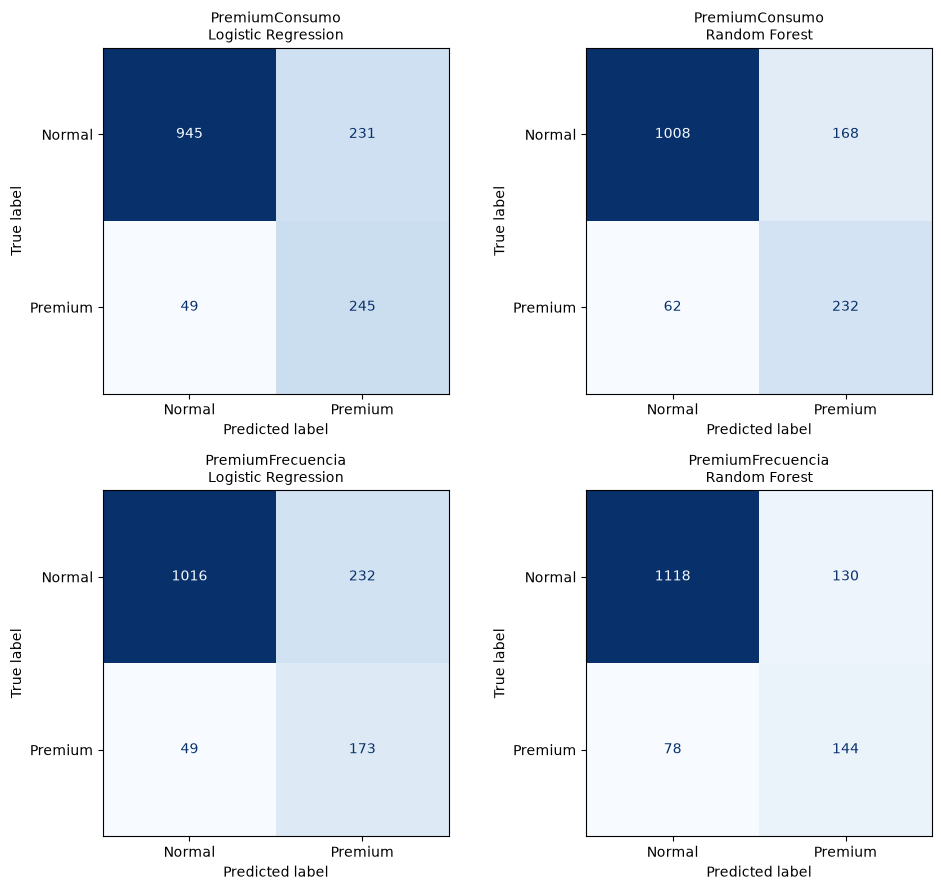

In [30]:
# Matrices de confusión
fig, axs = plt.subplots(2, 2, figsize = (10, 9))
for ax, ((etiqueta, nombre), (y_test, y_pred)) in zip(axs.flat, predClf.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels = ['Normal', 'Premium'],
                                            cmap = 'Blues', colorbar = False, ax = ax)
    ax.set_title(f'{etiqueta}\n{nombre}', fontsize = 10)
plt.tight_layout()
fig.savefig("confusion_matrices.png")
plt.show()

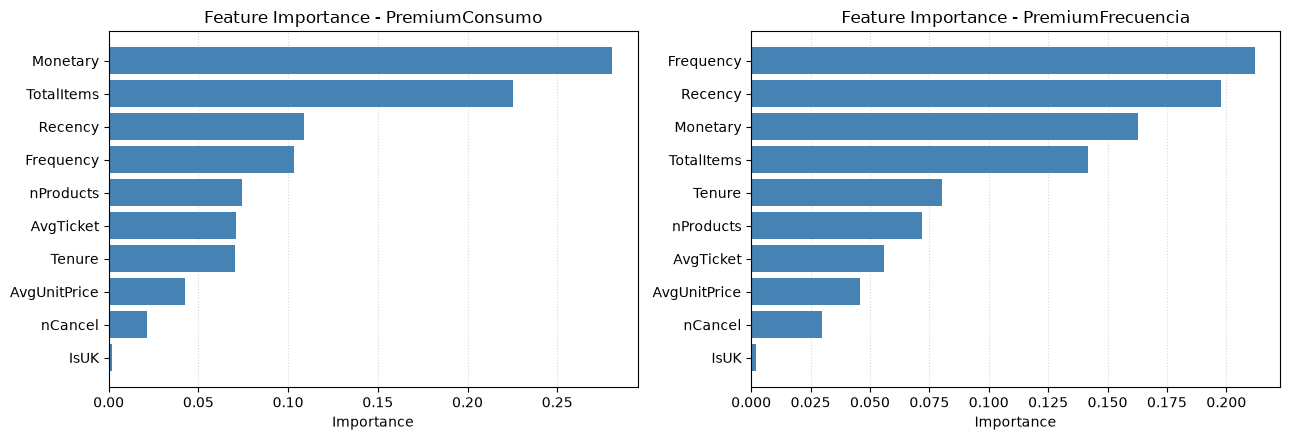

In [31]:
# Importancia de variables (Random Forest, reentrenado con todos los clientes)
fig, axs = plt.subplots(1, 2, figsize = (13, 4.5))
for ax, etiqueta in zip(axs, ['PremiumConsumo', 'PremiumFrecuencia']):
    rf = RandomForestClassifier(n_estimators = 300, min_samples_leaf = 5, class_weight = 'balanced',
                                random_state = 42, n_jobs = -1).fit(X, clientes[etiqueta])
    imp = pd.Series(rf.feature_importances_, index = varsCli).sort_values()
    ax.barh(imp.index, imp.values, color = 'steelblue')
    ax.set(xlabel = 'Importance', title = f'Feature Importance - {etiqueta}')
    ax.grid(axis = 'x', linestyle = ':', alpha = 0.5)
    ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig("feature_importance.png")
plt.show()

- Con un umbral del percentil 80, 20,01 % de los clientes resultó Premium por consumo (más de £948 en la ventana de etiqueta). Para frecuencia, el umbral fue de 3 facturas; como muchos clientes empatan en ese valor, solo el 15,09 % la supera. 627 clientes son Premium en ambas categorías.

- Los clientes Premium ya se diferenciaban en la ventana de observación: compraron más recientemente (recencia promedio de 64 días frente a 194), con mayor frecuencia (12,9 facturas frente a 3,3) y gastaron mucho más (£7.416 frente a £1.028), aunque con un precio unitario promedio menor, propio de compras al por mayor.

- **Ambos modelos alcanzan un AUC cercano a 0,90 para consumo y 0,87 para frecuencia, es decir, ordenan bien a los clientes según su probabilidad de ser Premium. El bosque aleatorio obtiene mejor exactitud y F1; la regresión logística detecta más Premium (mayor recall) a costa de más falsos positivos. La elección depende del uso: para una campaña de retención donde perder un Premium es costoso, conviene el modelo con mayor recall.**

- La precisión de la clase Premium (entre 0,43 y 0,58) indica que cerca de la mitad de los clientes señalados como Premium no lo fueron. Es esperable, porque se predice un comportamiento futuro y no una regla sobre los mismos datos.

- Para el consumo futuro, las variables más importantes son el gasto y las unidades compradas en el pasado. Para la frecuencia futura pesan más la frecuencia y la recencia. El país casi no aporta.

In [32]:
# Validación cruzada estratificada (k = 5) de los clasificadores
nFolds = 5
kFold = StratifiedKFold(n_splits = nFolds, shuffle = True, random_state = 42)
metricasCV = {'Accuracy': 'accuracy', 'Precision Premium': 'precision', 'Recall Premium': 'recall',
              'F1 Premium': 'f1', 'ROC AUC': 'roc_auc'}
resultadosCV = []
for etiqueta in ['PremiumConsumo', 'PremiumFrecuencia']:
    for nombre, modelo in modelos.items():
        cv = cross_validate(modelo, X, clientes[etiqueta], cv = kFold, scoring = metricasCV)
        fila = {'Etiqueta': etiqueta, 'Modelo': nombre}
        for metrica in metricasCV:
            fila[metrica] = f"{cv['test_' + metrica].mean():.3f} ± {cv['test_' + metrica].std():.3f}"
        ## AUC de cada partición, para ver su variación
        fila['ROC AUC por partición'] = cv['test_ROC AUC'].round(3).tolist()
        resultadosCV.append(fila)
#
resultadosCV = pd.DataFrame(resultadosCV)
## Comparación con la división única 70/30 (mismo orden de etiquetas y modelos)
resultadosCV['ROC AUC 70/30'] = resultadosClf['ROC AUC'].values
resultadosCV

,Etiqueta,Modelo,Accuracy,Precision Premium,Recall Premium,F1 Premium,ROC AUC,ROC AUC por partición,ROC AUC 70/30
0,PremiumConsumo,Logistic Regression,0.819 ± 0.008,0.530 ± 0.013,0.831 ± 0.039,0.647 ± 0.021,0.901 ± 0.009,"[0.911, 0.906, 0.901, 0.902, 0.884]",0.896
1,PremiumConsumo,Random Forest,0.840 ± 0.009,0.576 ± 0.016,0.754 ± 0.036,0.653 ± 0.022,0.898 ± 0.011,"[0.907, 0.904, 0.897, 0.904, 0.877]",0.898
2,PremiumFrecuencia,Logistic Regression,0.804 ± 0.012,0.422 ± 0.018,0.797 ± 0.023,0.551 ± 0.017,0.885 ± 0.003,"[0.885, 0.888, 0.889, 0.886, 0.88]",0.872
3,PremiumFrecuencia,Random Forest,0.846 ± 0.008,0.495 ± 0.018,0.686 ± 0.034,0.574 ± 0.010,0.878 ± 0.005,"[0.877, 0.888, 0.88, 0.872, 0.876]",0.871


**Validación cruzada (k = 5)**

- Los resultados de la validación cruzada son consistentes con los de la división única 70/30: el AUC promedio es de 0,90 para consumo y de 0,88–0,89 para frecuencia, con desviaciones entre particiones de 0,011 o menos. Los modelos son estables y su desempeño no depende de qué clientes caen en el conjunto de prueba. La división 70/30 fue algo pesimista para la frecuencia (AUC de 0,872 y 0,871, por debajo de las cinco particiones de la regresión logística y en el límite inferior de las del bosque aleatorio).

- En consumo, la ventaja del bosque aleatorio que mostraba la división 70/30 en AUC (0,898 frente a 0,896) no se sostiene: con validación cruzada la regresión logística obtiene 0,901 ± 0,009 y el bosque aleatorio 0,898 ± 0,011, una diferencia menor que la variación entre particiones. En frecuencia, la regresión logística es algo mejor (0,885 ± 0,003 frente a 0,878 ± 0,005) y supera o iguala al bosque aleatorio en las cinco particiones. Es decir, el modelo más simple ordena a los clientes igual o mejor que el bosque aleatorio.

- Se confirma la diferencia de comportamiento entre ambos modelos: el bosque aleatorio tiene mayor exactitud y precisión, y la regresión logística detecta más clientes Premium (recall de 0,83 frente a 0,75 en consumo y de 0,80 frente a 0,69 en frecuencia). El recall es la métrica más variable entre particiones (desviación de hasta 0,039).

- La precisión de la clase Premium se mantiene en promedio entre 0,42 y 0,58, con poca variación entre particiones (desviación de 0,018 o menos), por lo que la proporción de falsos positivos es una característica del problema (predecir comportamiento futuro) y no un efecto de la división de los datos.

- Con estos resultados, la regresión logística es la opción recomendada: tiene igual o mejor capacidad de ordenamiento, mayor sensibilidad, y es más sencilla de interpretar. El bosque aleatorio es preferible solo si se busca reducir los falsos positivos, por ejemplo cuando cada cliente señalado como Premium implica un costo de atención.

### Parte 2: Segmentación de clientes

Se segmenta a los clientes con su comportamiento en todo el periodo, usando las variables RFM:
- **Recency:** días desde la última compra hasta el día siguiente a la última fecha del conjunto de datos;
- **Frequency:** número de facturas; y
- **Monetary:** gasto total.

Las tres variables tienen distribuciones muy sesgadas, por lo que se transforman con logaritmo y se estandarizan antes de agrupar; de lo contrario, los pocos clientes mayoristas dominarían las distancias.

In [33]:
# Tabla RFM con todo el periodo
fechaRef = df_cli['InvoiceDate'].max() + pd.Timedelta(days = 1)
rfm = df_cli.groupby('CustomerID').agg(
    LastDate = ('InvoiceDate', 'max'),
    Frequency = ('InvoiceNo', 'nunique'),
    Monetary = ('TotalSale', 'sum')
)
rfm['Recency'] = (fechaRef - rfm['LastDate']).dt.days
rfm = rfm[['Recency', 'Frequency', 'Monetary']]
#
# Transformación logarítmica (variables muy sesgadas) y estandarización
X_rfm = StandardScaler().fit_transform(np.log1p(rfm))
rfm.describe().round(2)

,Recency,Frequency,Monetary
count,5839.00,5839.00,5839.00
mean,200.30,6.24,2829.61
std,208.62,12.68,13900.56
min,1.00,1.00,2.90
25%,25.00,1.00,336.24
50%,95.00,3.00,851.01
75%,379.00,7.00,2206.94
max,739.00,371.00,579128.64


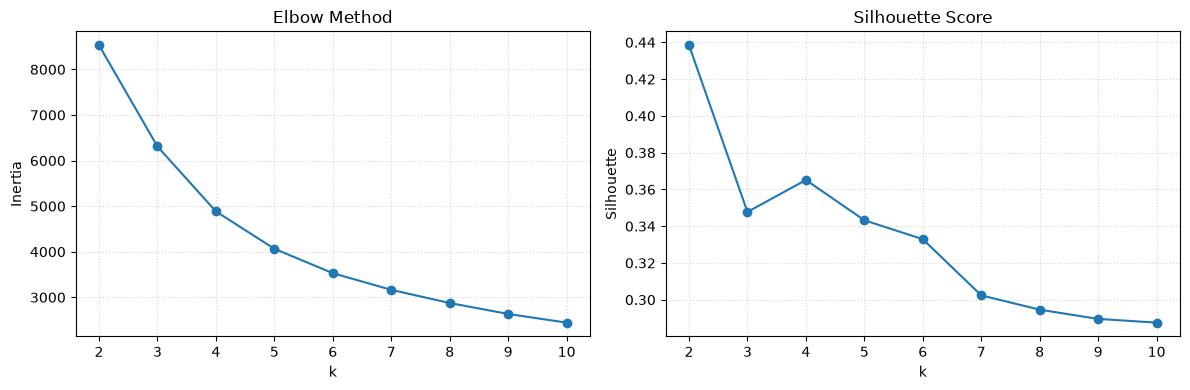

 k  Inertia  Silhouette
 2 8531.606       0.438
 3 6309.339       0.348
 4 4885.320       0.365
 5 4064.950       0.343
 6 3529.543       0.333
 7 3164.199       0.302
 8 2874.895       0.295
 9 2634.871       0.290
10 2444.642       0.288


In [34]:
# K-means: método del codo y coeficiente de silueta
rangoK = range(2, 11)
inercias, siluetas = [], []
for k in rangoK:
    km = KMeans(n_clusters = k, n_init = 10, random_state = 42).fit(X_rfm)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_rfm, km.labels_))
#
fig, axs = plt.subplots(1, 2, figsize = (12, 4))
axs[0].plot(list(rangoK), inercias, marker = 'o')
axs[0].set(xlabel = 'k', ylabel = 'Inertia', title = 'Elbow Method')
axs[1].plot(list(rangoK), siluetas, marker = 'o')
axs[1].set(xlabel = 'k', ylabel = 'Silhouette', title = 'Silhouette Score')
for ax in axs:
    ax.grid(linestyle = ':', alpha = 0.5)
plt.tight_layout()
plt.show()
print(pd.DataFrame({'k': list(rangoK), 'Inertia': inercias, 'Silhouette': siluetas}).round(3).to_string(index = False))

El coeficiente de silueta es máximo con k = 2, pero esa partición solo separa clientes activos de inactivos. Con k = 4 hay un máximo local de silueta y el codo de la inercia empieza a aplanarse, por lo que se elige k = 4 para obtener segmentos más útiles.

In [35]:
# Modelo K-means final
kElegido = 4
kmeans = KMeans(n_clusters = kElegido, n_init = 10, random_state = 42).fit(X_rfm)
rfm['KMeans'] = kmeans.labels_
## Renumeración de los grupos de mayor a menor gasto mediano (0 = mayor valor)
ordenKM = rfm.groupby('KMeans')['Monetary'].median().sort_values(ascending = False).index
rfm['KMeans'] = rfm['KMeans'].map({grupo: i for i, grupo in enumerate(ordenKM)})
#
# Perfil de cada segmento
perfilKM = rfm.groupby('KMeans').agg(
    nCustomers = ('Recency', 'size'),
    Recency = ('Recency', 'median'),
    Frequency = ('Frequency', 'median'),
    Monetary = ('Monetary', 'median'),
    TotalMonetary = ('Monetary', 'sum')
)
perfilKM['%Customers'] = perfilKM['nCustomers'] * 100 / perfilKM['nCustomers'].sum()
perfilKM['%Revenue'] = perfilKM['TotalMonetary'] * 100 / perfilKM['TotalMonetary'].sum()
perfilKM.round(2)

,nCustomers,Recency,Frequency,Monetary,TotalMonetary,%Customers,%Revenue
KMeans,,,,,,,
0,1183,17.0,13.0,4861.72,12145873.40,20.26,73.51
1,1448,183.5,4.0,1444.80,2724450.46,24.80,16.49
2,1246,24.0,3.0,711.77,1037268.30,21.34,6.28
3,1962,401.0,1.0,269.15,614499.38,33.60,3.72


In [36]:
# Mean Shift
## Ancho de banda estimado a partir de los datos (parámetro: cuantil)
qBanda = 0.15
banda = estimate_bandwidth(X_rfm, quantile = qBanda, n_samples = 2000, random_state = 42)
meanShift = MeanShift(bandwidth = banda, bin_seeding = True, n_jobs = -1).fit(X_rfm)
rfm['MeanShift'] = meanShift.labels_
## Renumeración de los grupos de mayor a menor gasto mediano (0 = mayor valor)
ordenMS = rfm.groupby('MeanShift')['Monetary'].median().sort_values(ascending = False).index
rfm['MeanShift'] = rfm['MeanShift'].map({grupo: i for i, grupo in enumerate(ordenMS)})
print("Ancho de banda:", round(banda, 3), "| Grupos encontrados:", rfm['MeanShift'].nunique())
#
perfilMS = rfm.groupby('MeanShift').agg(
    nCustomers = ('Recency', 'size'),
    Recency = ('Recency', 'median'),
    Frequency = ('Frequency', 'median'),
    Monetary = ('Monetary', 'median'),
    TotalMonetary = ('Monetary', 'sum')
)
perfilMS['%Customers'] = perfilMS['nCustomers'] * 100 / perfilMS['nCustomers'].sum()
perfilMS['%Revenue'] = perfilMS['TotalMonetary'] * 100 / perfilMS['TotalMonetary'].sum()
perfilMS.round(2)

Ancho de banda: 1.058 | Grupos encontrados: 3


,nCustomers,Recency,Frequency,Monetary,TotalMonetary,%Customers,%Revenue
MeanShift,,,,,,,
0,54,23.0,45.5,52408.72,4637641.83,0.92,28.07
1,939,14.0,14.0,5311.96,6829393.12,16.08,41.33
2,4846,170.0,2.0,628.12,5055056.59,82.99,30.60


In [37]:
# Sensibilidad de Mean Shift al ancho de banda
sensMS = []
for q in [0.1, 0.15, 0.2, 0.25, 0.3]:
    b = estimate_bandwidth(X_rfm, quantile = q, n_samples = 2000, random_state = 42)
    lab = MeanShift(bandwidth = b, bin_seeding = True, n_jobs = -1).fit_predict(X_rfm)
    tamanios = pd.Series(lab).value_counts()
    sensMS.append({'Quantile': q, 'Bandwidth': round(b, 3), 'nClusters': tamanios.size,
                   'Largest cluster %': round(tamanios.iloc[0] * 100 / len(lab), 1),
                   'Silhouette': round(silhouette_score(X_rfm, lab), 3) if tamanios.size > 1 else np.nan})
pd.DataFrame(sensMS)

,Quantile,Bandwidth,nClusters,Largest cluster %,Silhouette
0,0.10,0.889,8,56.0,0.255
1,0.15,1.058,3,83.0,0.396
2,0.20,1.211,2,93.2,0.435
3,0.25,1.362,2,91.4,0.427
4,0.30,1.505,1,100.0,NaN


Varianza explicada PCA: [0.764 0.188] | Total: 0.951


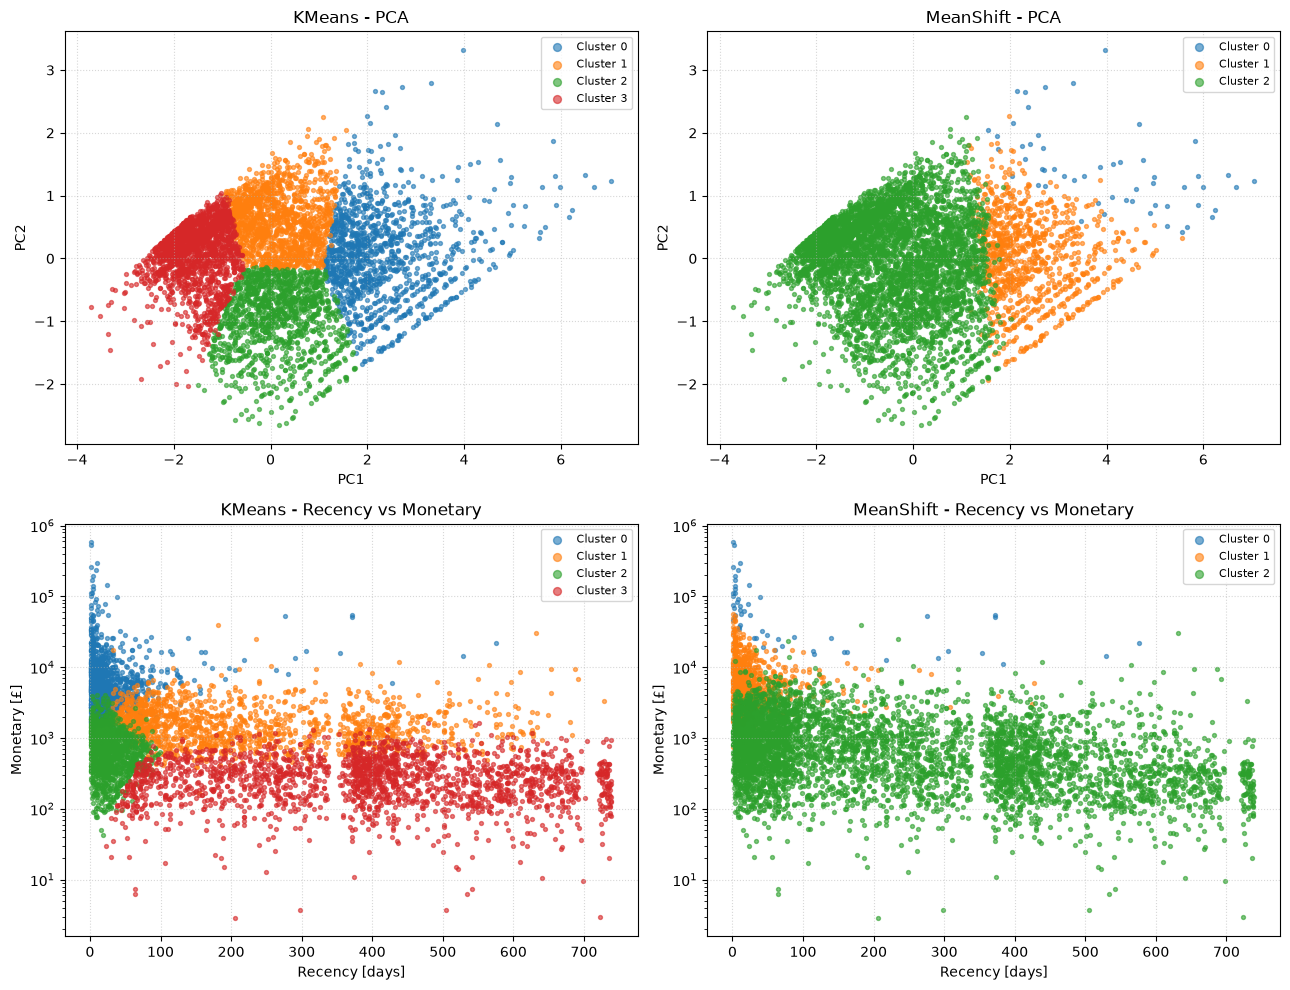

In [38]:
# Visualización de ambos agrupamientos (PCA a 2 componentes y Recency vs Monetary)
pca = PCA(n_components = 2).fit(X_rfm)
X_pca = pca.transform(X_rfm)
print("Varianza explicada PCA:", pca.explained_variance_ratio_.round(3), "| Total:", round(pca.explained_variance_ratio_.sum(), 3))
#
fig, axs = plt.subplots(2, 2, figsize = (13, 10))
for j, metodo in enumerate(['KMeans', 'MeanShift']):
    for grupo in sorted(rfm[metodo].unique()):
        sel = (rfm[metodo] == grupo).values
        axs[0, j].scatter(X_pca[sel, 0], X_pca[sel, 1], s = 8, alpha = 0.6, label = f'Cluster {grupo}')
        axs[1, j].scatter(rfm.loc[sel, 'Recency'], rfm.loc[sel, 'Monetary'], s = 8, alpha = 0.6, label = f'Cluster {grupo}')
    axs[0, j].set(xlabel = 'PC1', ylabel = 'PC2', title = f'{metodo} - PCA')
    axs[1, j].set(xlabel = 'Recency [days]', ylabel = 'Monetary [£]', yscale = 'log', title = f'{metodo} - Recency vs Monetary')
    for i in range(2):
        axs[i, j].grid(linestyle = ':', alpha = 0.5)
        axs[i, j].legend(fontsize = 8, markerscale = 2)
plt.tight_layout()
fig.savefig("clusters.png")
plt.show()

In [39]:
# Comparación de ambos métodos
compSeg = pd.DataFrame({
    'nClusters': [rfm['KMeans'].nunique(), rfm['MeanShift'].nunique()],
    'Silhouette': [silhouette_score(X_rfm, rfm['KMeans']), silhouette_score(X_rfm, rfm['MeanShift'])],
    'Davies-Bouldin': [davies_bouldin_score(X_rfm, rfm['KMeans']), davies_bouldin_score(X_rfm, rfm['MeanShift'])],
    'Largest cluster %': [rfm['KMeans'].value_counts(normalize = True).iloc[0] * 100,
                          rfm['MeanShift'].value_counts(normalize = True).iloc[0] * 100]
}, index = ['K-means', 'Mean Shift']).round(3)
print(compSeg,
      "\n\nÍndice de Rand ajustado entre ambos agrupamientos:", round(adjusted_rand_score(rfm['KMeans'], rfm['MeanShift']), 3),
      "\n\nTabla cruzada (filas: K-means, columnas: Mean Shift):\n", pd.crosstab(rfm['KMeans'], rfm['MeanShift']))

            nClusters  Silhouette  Davies-Bouldin  Largest cluster %
K-means             4       0.365           0.932             33.602
Mean Shift          3       0.396           1.049             82.994 

Índice de Rand ajustado entre ambos agrupamientos: 0.194 

Tabla cruzada (filas: K-means, columnas: Mean Shift):
 MeanShift   0    1     2
KMeans                  
0          53  923   207
1           1   11  1436
2           0    5  1241
3           0    0  1962


**Segmentos K-means (k = 4)**
- **Grupo 0 – Clientes de alto valor:** 20,3 % de los clientes y 73,5 % del gasto. Compran con frecuencia (mediana de 13 facturas), lo hicieron recientemente (mediana de 17 días) y tienen un gasto mediano de £4.862.
- **Grupo 1 – Clientes valiosos en riesgo:** 24,8 % de los clientes y 16,5 % del gasto. Gasto y frecuencia intermedios, pero sin comprar hace unos seis meses (mediana de 184 días).
- **Grupo 2 – Clientes recientes de bajo valor:** 21,3 % de los clientes y 6,3 % del gasto. Compraron hace poco (24 días), pero pocas veces y por montos bajos; incluye clientes nuevos.
- **Grupo 3 – Clientes perdidos:** 33,6 % de los clientes y solo 3,7 % del gasto. Una sola compra (mediana) hace más de un año.

**Segmentos Mean Shift (cuantil 0,15)**
- **Grupo 0 – Mayoristas principales:** 54 clientes (0,9 %) que generan el 28,1 % del gasto, con una mediana de 46 facturas y £52.409.
- **Grupo 1 – Clientes frecuentes de alto valor:** 16,1 % de los clientes y 41,3 % del gasto.
- **Grupo 2 – Resto de clientes:** 83 % de los clientes y 30,6 % del gasto.

**Comparación**
- K-means obliga a definir k y genera grupos de tamaño similar que dividen el espacio en regiones parecidas; es útil para acciones sobre toda la base (por ejemplo, reactivar al grupo en riesgo).
- Mean Shift encuentra el número de grupos por sí mismo a partir de la densidad, pero depende mucho del ancho de banda: con cuantil 0,10 encuentra 8 grupos, con 0,15 encuentra 3, con 0,20 a 0,25 encuentra 2 y con 0,30 uno solo. Como la mayor parte de los clientes se concentra en una zona densa, el método deja a la mayoría en un solo grupo y aísla a los clientes extremos, lo que es útil para identificar a los mayoristas principales.
- Mean Shift obtiene una silueta algo mayor (0,396 frente a 0,365), pero K-means tiene mejor índice de Davies-Bouldin (0,932 frente a 1,049, menor es mejor). La silueta de Mean Shift se ve favorecida porque separa un grupo pequeño muy alejado del resto.
- El índice de Rand ajustado entre ambas particiones es bajo (0,194): coinciden en separar a los clientes de alto valor (976 de los 1.183 clientes del Grupo 0 de K-means, el 82,5 %, quedan en los Grupos 0 y 1 de Mean Shift), pero Mean Shift no distingue entre clientes en riesgo, recientes y perdidos.
- Para fines de negocio, ambas técnicas son complementarias: K-means para segmentar toda la cartera y Mean Shift para detectar el pequeño grupo de clientes que concentra una parte desproporcionada del gasto.

### Parte 3: Predicción de ventas

Se predice la **venta diaria total** (£) a partir de su historial. El conjunto de datos no tiene categorías de productos, por lo que se construyen características temporales:
- **Calendario:** día de la semana, mes, día del mes, semana del año, día del año y si el día pertenece al cuarto trimestre (temporada alta); y
- **Rezagos:** ventas del día anterior, de hace 7 y 14 días, del mismo día de la semana un año antes (`Lag364`), y promedios móviles de los 7 y 28 días previos.

Todos los rezagos usan solo información de días anteriores, para no filtrar información del día que se predice. Como `Lag364` requiere un año de historial, la serie para modelado empieza a finales de noviembre de 2010.

La división entre entrenamiento y prueba es temporal: se entrena con los días anteriores al 01/09/2011 y se prueba con septiembre a diciembre de 2011, que incluye la temporada alta. Mezclar fechas al azar permitiría que el modelo aprenda del futuro.

Se comparan tres modelos: una referencia ingenua (la venta de hace 7 días), una regresión lineal y un bosque aleatorio. Las métricas son el error absoluto medio (MAE), la raíz del error cuadrático medio (RMSE), el error porcentual absoluto medio (MAPE) y el coeficiente de determinación (R²).

In [40]:
# Serie diaria de ventas (calendario completo, 0 en días sin ventas)
ventas = df_mod.groupby(df_mod['InvoiceDate'].dt.normalize())['TotalSale'].sum()
ventas = ventas.reindex(pd.date_range(ventas.index.min(), ventas.index.max(), freq = 'D'), fill_value = 0)
serie = ventas.to_frame('Sales')
serie.index.name = 'Date'
#
# Características de calendario
serie['DayOfWeek'] = serie.index.dayofweek
serie['Month'] = serie.index.month
serie['DayOfMonth'] = serie.index.day
serie['WeekOfYear'] = serie.index.isocalendar().week.astype(int)
serie['DayOfYear'] = serie.index.dayofyear
serie['IsQ4'] = (serie.index.quarter == 4).astype(int)
# Características de rezago (solo información de días anteriores)
serie['Lag1'] = serie['Sales'].shift(1)
serie['Lag7'] = serie['Sales'].shift(7)
serie['Lag14'] = serie['Sales'].shift(14)
serie['Lag364'] = serie['Sales'].shift(364)                       # mismo día de la semana, un año antes
serie['Roll7'] = serie['Sales'].shift(1).rolling(7).mean()
serie['Roll28'] = serie['Sales'].shift(1).rolling(28).mean()
#
# Solo días con operación (la tienda casi no opera los sábados y cierra en feriados de fin de año)
serie = serie.loc[serie['Sales'] > 0].dropna()
print("Días disponibles para modelado:", len(serie), "|", serie.index.min().date(), "a", serie.index.max().date())
serie.head()

Días disponibles para modelado: 306 | 2010-11-30 a 2011-12-09


,Sales,DayOfWeek,Month,DayOfMonth,WeekOfYear,DayOfYear,IsQ4,Lag1,Lag7,Lag14,Lag364,Roll7,Roll28
Date,,,,,,,,,,,,,
2010-11-30,59212.51,1,11,30,48,334,1,76693.36,53988.42,70062.19,51813.89,46630.105714,47471.408571
2010-12-01,57173.48,2,12,1,48,335,1,59212.51,59646.87,50237.32,61462.20,47376.404286,48010.505000
2010-12-02,47461.97,3,12,2,48,336,1,57173.48,70975.04,43790.12,70301.56,47023.062857,48475.477857
2010-12-03,44370.50,4,12,3,48,337,1,47461.97,38654.54,44700.82,38985.52,43664.052857,47032.893214
2010-12-05,30664.02,6,12,5,48,339,1,0.00,26452.51,31198.17,24035.17,44480.618571,46991.386071


In [41]:
# División temporal entrenamiento / prueba (sin mezclar el orden)
fechaPrueba = pd.Timestamp('2011-09-01')
varsSerie = ['DayOfWeek', 'Month', 'DayOfMonth', 'WeekOfYear', 'DayOfYear', 'IsQ4',
             'Lag1', 'Lag7', 'Lag14', 'Lag364', 'Roll7', 'Roll28']
X_train, y_train = serie.loc[serie.index < fechaPrueba, varsSerie], serie.loc[serie.index < fechaPrueba, 'Sales']
X_test, y_test = serie.loc[serie.index >= fechaPrueba, varsSerie], serie.loc[serie.index >= fechaPrueba, 'Sales']
print("Entrenamiento:", len(X_train), "días | Prueba:", len(X_test), "días")
#
# Modelos
regresores = {
    'Baseline (Lag7)': None,
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators = 500, min_samples_leaf = 3, random_state = 42, n_jobs = -1)
}
resultadosReg = []
predReg = {}
for nombre, modelo in regresores.items():
    if modelo is None:
        y_pred = X_test['Lag7'].values          # referencia ingenua: misma venta que hace una semana
    else:
        y_pred = modelo.fit(X_train, y_train).predict(X_test)
    predReg[nombre] = y_pred
    resultadosReg.append({'Modelo': nombre,
                          'MAE [£]': mean_absolute_error(y_test, y_pred),
                          'RMSE [£]': root_mean_squared_error(y_test, y_pred),
                          'MAPE [%]': mean_absolute_percentage_error(y_test, y_pred) * 100,
                          'R2': r2_score(y_test, y_pred)})
resultadosReg = pd.DataFrame(resultadosReg).round(3)
resultadosReg

Entrenamiento: 220 días | Prueba: 86 días


,Modelo,MAE [£],RMSE [£],MAPE [%],R2
0,Baseline (Lag7),15374.707,20158.567,37.073,-0.132
1,Linear Regression,11589.645,15587.500,27.073,0.323
2,Random Forest,11394.993,16083.712,27.019,0.279


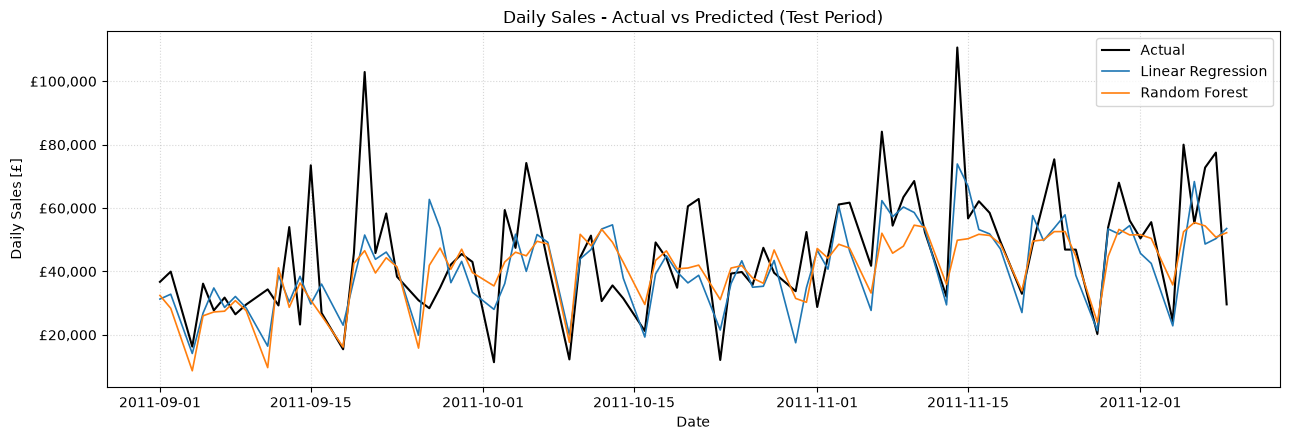

Importancia de variables (Random Forest):
 Lag364        0.278
Lag7          0.167
Roll7         0.131
DayOfWeek     0.128
Lag1          0.097
Roll28        0.056
Lag14         0.050
DayOfMonth    0.048
DayOfYear     0.028
WeekOfYear    0.012
Month         0.006
IsQ4          0.001
dtype: float64


In [42]:
# Valores reales vs predichos en el periodo de prueba
fig, ax = plt.subplots(figsize = (13, 4.5))
ax.plot(y_test.index, y_test.values, color = 'black', linewidth = 1.5, label = 'Actual')
for nombre in ['Linear Regression', 'Random Forest']:
    ax.plot(y_test.index, predReg[nombre], linewidth = 1.2, label = nombre)
ax.set(xlabel = 'Date', ylabel = 'Daily Sales [£]', title = 'Daily Sales - Actual vs Predicted (Test Period)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'£{x:,.0f}'))
ax.grid(linestyle = ':', alpha = 0.5)
ax.legend()
plt.tight_layout()
fig.savefig("sales_prediction.png")
plt.show()
#
# Importancia de variables del bosque aleatorio
impReg = pd.Series(regresores['Random Forest'].feature_importances_, index = varsSerie).sort_values(ascending = False)
print("Importancia de variables (Random Forest):\n", impReg.round(3))

In [43]:
# Agregado mensual del periodo de prueba (real vs predicho)
mesPrueba = pd.DataFrame({'Actual': y_test.values,
                          'Random Forest': predReg['Random Forest'],
                          'Linear Regression': predReg['Linear Regression']},
                         index = y_test.index).groupby(y_test.index.to_period('M')).sum()
mesPrueba['Error RF %'] = (mesPrueba['Random Forest'] - mesPrueba['Actual']) * 100 / mesPrueba['Actual']
mesPrueba.round(2)

,Actual,Random Forest,Linear Regression,Error RF %
Date,,,,
2011-09,1017707.19,844733.50,911537.65,-17.00
2011-10,1073170.38,1071073.24,999623.44,-0.20
2011-11,1441522.29,1219910.13,1302433.53,-15.37
2011-12,445445.81,403207.90,379103.19,-9.48


- Ambos modelos mejoran claramente a la referencia ingenua: el MAE baja de unas £15.400 a unas £11.400–11.600 por día, y el MAPE de 37 % a 27 %.

- La regresión lineal y el bosque aleatorio tienen un desempeño muy similar (R² de 0,32 y 0,28, respectivamente). El bosque aleatorio no aporta una mejora clara, probablemente porque solo hay 220 días de entrenamiento.

- El R² moderado se explica por la naturaleza de las ventas: buena parte proviene de pedidos mayoristas puntuales que generan picos difíciles de anticipar con información de calendario (por ejemplo, los picos de más de £100.000 en septiembre y noviembre). Los modelos siguen bien la tendencia y el patrón semanal, pero suavizan esos picos.

- Las variables más importantes para el bosque aleatorio son la venta del mismo día un año antes, la de hace una semana, el promedio de los 7 días previos y el día de la semana, lo que confirma la estacionalidad anual y semanal observada en el análisis exploratorio.

- Al agregar las predicciones por mes, el error del bosque aleatorio es bajo en octubre (−0,2 %), pero subestima septiembre (−17 %) y noviembre (−15 %), meses con varios pedidos grandes puntuales.

### Conclusiones

- La limpieza mostró que la regla de emparejar cancelaciones por el mismo código de factura no aplica a este conjunto de datos, porque las facturas 'C' tienen numeración propia. El emparejamiento por cliente, producto y monto eliminó un tercio de las cancelaciones con cliente. Además, el traslape entre las dos hojas del archivo explica dos tercios de los registros duplicados.

- Las ventas son muy estacionales, con un máximo en noviembre y mayor actividad de lunes a jueves en horario laboral, y dependen de un grupo reducido de clientes mayoristas.

- Con el historial de compras se puede anticipar qué clientes serán Premium en los meses siguientes, con un AUC cercano a 0,90 por consumo y 0,87 por frecuencia.

- K-means (k = 4) generó segmentos accionables sobre toda la cartera. Mean Shift aisló un grupo de 54 mayoristas que genera más de la cuarta parte del gasto.

- La predicción de la venta diaria mejora a la referencia ingenua, pero queda limitada por los pedidos mayoristas puntuales. Información adicional, como categorías de productos o pedidos programados, podría mejorarla.